<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="https://www.uoc.edu/content/dam/news/images/noticies/2016/202-nova-marca-uoc.jpg" align="left" width="45%">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">M2.891 · Aprendizaje automático · PEC3</p>
<p style="margin: 0; text-align:right;">2026-2 · Máster universitario en Ciencia de datos (Data science)</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Estudios de Informática, Multimedia y Telecomunicación</p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>

# PEC 3: Métodos supervisados

En esta práctica estudiaremos los métodos supervisados de tres maneras. En la sección 1 los compararemos sobre un problema de dos dimensiones, donde se puede ver cómo decide cada uno. En la sección 2 los aplicaremos a un problema real de reingresos hospitalarios, donde lo difícil no es entrenar un modelo sino validarlo bien, decidir con sus probabilidades y anticipar cómo funcionará con datos nuevos. En la sección 3 revisaremos la solución que un asistente de IA ha dado a otro problema, la predicción del abandono de asignaturas en una universidad en línea, para encontrar, corregir y medir sus errores.

**Índice**

- [1. Los modelos por su comportamiento](#ej1)
    - [1.1. Carga de datos, validación cruzada y efecto del escalado](#ej1_1)
    - [1.2. Comparación de modelos con búsqueda de hiperparámetros y fronteras](#ej1_2)
    - [1.3. Identificar el modelo](#ej1_3)
    - [1.4. Sesgo y varianza con bootstrap](#ej1_4)
- [2. Caso práctico: reingresos hospitalarios](#ej2)
    - [2.1. Carga y exploración orientada a decidir](#ej2_1)
    - [2.2. Validación honesta y comparación de modelos](#ej2_2)
    - [2.3. Decisión con la matriz de costes](#ej2_3)
    - [2.4. Efectos de las variables, interpretación y contraste con la literatura](#ej2_4)
    - [2.5. Equidad](#ej2_5)
    - [2.6. Estimación del resultado en el test oculto](#ej2_6)
    - [2.7. Entrega de predicciones para el test oculto](#ej2_7)
- [3. Auditoría de una solución hecha por IA](#ej3)
    - [3.1. Revisión del notebook](#ej3_1)
    - [3.2. Corrección y cuantificación](#ej3_2)
    - [3.3. Conclusiones](#ej3_3)

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Sobre las respuestas de análisis.</strong> Las respuestas deben ser breves y centrarse en vuestros propios resultados: citad la tabla, la figura o la cifra en la que os apoyáis. Se valora la capacidad de síntesis. Las respuestas de análisis se escriben en la celda de color verde con el título «Respuesta», y solo allí: no en comentarios de código, ni en celdas nuevas, ni en otros bloques.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Nombre y apellidos: Adrián Moreno García</strong>

</td></tr></table>

**Consideraciones generales**

- La solución no puede utilizar métodos, funciones o parámetros declarados *deprecated*.
- Esta PEC debe realizarse de forma estrictamente individual. Cualquier indicio de copia será penalizado con un suspenso (D) para todas las partes implicadas y la posible evaluación negativa de la asignatura de forma íntegra.
- Es necesario indicar todas las fuentes utilizadas. De no ser así, se considerará plagio.
- **Uso de herramientas de inteligencia artificial.** Podéis utilizar herramientas de IA generativa como apoyo, por ejemplo para consultar conceptos, depurar código o mejorar la presentación de los gráficos. Sois responsables de todo lo que entreguéis, incluido lo que os haya propuesto una IA: si contiene errores, los errores son vuestros. El análisis de los datos y las respuestas de las celdas «Respuesta» deben ser de autoría propia. Cada uso de IA se declara en el lugar donde se ha producido, con un comentario en la celda de código o una nota al final de la respuesta, indicando la herramienta y el modelo concreto (por ejemplo, «Claude Opus 5.5» o «ChatGPT con GPT-5»), para qué se ha usado y qué habéis modificado de lo que propuso. Al final del notebook, la tabla [Declaración de uso de IA](#declaracion_ia) recoge todos los usos. Declarar el uso de IA no resta puntos; no declararlo se considerará plagio. Las referencias bibliográficas que os sugiera una IA deben comprobarse antes de citarlas: una cita inexistente, o que no dice lo que se le atribuye, anula el apartado en el que aparece.

**Formato de la entrega.** Notebook (`.ipynb`), su exportación a HTML con todas las salidas, y los dos ficheros CSV del apartado 2.7.

<a id='ej1'></a>
# 1. Los modelos por su comportamiento (3 puntos)

En esta sección vais a **conocer los clasificadores por cómo se comportan**, no por su fórmula: compararéis k-NN, SVM (kernels lineal, polinomial, radial y sigmoide), árboles de decisión, naive Bayes gaussiano, LDA, QDA y regresión logística sobre un mismo problema sintético en dos dimensiones, y explicaréis **dónde** del plano falla cada uno y **por qué**.

El fichero `datos_2d.csv` contiene 1500 puntos con tres variables, `x1`, `x2` y `x3`, y la columna `clase` (0, 1 o 2). Todos los modelos que se dibujan se entrenan **solo con `x1` y `x2`**, de modo que sus fronteras se pueden pintar en el plano; `x3` se usa únicamente en el apartado 1.1.

Para hablar de zonas concretas usaremos cuatro regiones del plano (función `assign_region`, definida más abajo):

| región | definición |
|---|---|
| `LEFT` | `x1 < -1.8` y `x2 > -1` |
| `CENTER` | `-1.8 <= x1 <= 1.8` y `x2 > -1` |
| `RIGHT` | `x1 > 1.8` y `x2 > -1` |
| `BAND` | `x2 <= -1` |

| apartado | tema | puntos |
|---|---|---|
| 1.1 | Carga de datos, validación cruzada y efecto del escalado (variable `x3`) | 0,50 |
| 1.2 | Comparación de modelos con búsqueda de hiperparámetros y fronteras | 1,00 |
| 1.3 | Identificar seis modelos a partir de sus fronteras | 1,00 |
| 1.4 | Sesgo y varianza con remuestreo bootstrap | 0,50 |

<table width="100%"><tr><td bgcolor="#fcf8e3" style="border-left:6px solid #8a6d3b; color:#4a3a12; padding:10px 14px;">

🟨 <strong>Aviso sobre las respuestas de análisis:</strong> deben ser <strong>breves</strong> (unas pocas frases por pregunta) y estar <strong>centradas en vuestros propios resultados</strong>: citad cifras obtenidas en vuestras ejecuciones y zonas concretas del plano (por ejemplo, la región o las coordenadas aproximadas). Las respuestas genéricas, que valdrían para cualquier conjunto de datos, no puntúan.

</td></tr></table>

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, to_rgb
from IPython.display import Image, display

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score

warnings.filterwarnings('ignore')
pd.set_option('display.precision', 3)
pd.set_option('display.width', 160)

# Stratified 5-fold cross-validation, used throughout section 1
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Fixed color for each class (classes 0, 1 and 2), used in all the figures
CLASS_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c']


def make_grid(X, n=300, margin=0.5):
    """n x n grid of points covering the range of the data X (2 columns) plus a margin.
    Returns (xx, yy), two n x n matrices."""
    X = np.asarray(X, dtype=float)
    x1 = np.linspace(X[:, 0].min() - margin, X[:, 0].max() + margin, n)
    x2 = np.linspace(X[:, 1].min() - margin, X[:, 1].max() + margin, n)
    return np.meshgrid(x1, x2)


def predict_grid(model, xx, yy):
    """Class predicted by an already fitted model at each grid point (matrix with the shape of xx)."""
    P = np.c_[xx.ravel(), yy.ravel()]
    if hasattr(model, 'feature_names_in_'):          # model fitted with a DataFrame
        P = pd.DataFrame(P, columns=model.feature_names_in_)
    return np.asarray(model.predict(P)).reshape(xx.shape)


def plot_boundary(model, X_grid, X_points=None, y_points=None, ax=None,
                  n=300, margin=0.5, size=14, title=None, contour=False):
    """Plot the decision regions of an ALREADY FITTED model (trained only with x1 and x2).

    model    : classifier fitted with 2 variables (x1, x2).
    X_grid   : data (n x 2) that set the range of the grid (n points per axis, not a fixed step).
               Always use the same data so that all figures have the same axes.
    X_points, y_points : points (and their class) drawn on top; optional.
    ax       : matplotlib axis to draw on (to build grids of plots); if None, a new one is created.
    The class colors are fixed (CLASS_COLORS), even if the model does not predict some class."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    xx, yy = make_grid(X_grid, n=n, margin=margin)
    Z = predict_grid(model, xx, yy)
    cmap = ListedColormap(CLASS_COLORS)
    ax.pcolormesh(xx, yy, Z, cmap=cmap, vmin=-0.5, vmax=2.5, alpha=0.30,
                  shading='nearest', rasterized=True)
    if contour:
        ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors='k', linewidths=0.6)
    if X_points is not None:
        X_points = np.asarray(X_points, dtype=float)
        ax.scatter(X_points[:, 0], X_points[:, 1], c=np.asarray(y_points), cmap=cmap,
                   vmin=-0.5, vmax=2.5, s=size, edgecolor='k', linewidth=0.3)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    if title:
        ax.set_title(title, fontsize=9)
    return ax


# Four regions of the (x1, x2) plane, to refer to places and to compute results per region
REGIONS = ['LEFT', 'CENTER', 'RIGHT', 'BAND']


def assign_region(x1, x2):
    """LEFT: x1 < -1.8 and x2 > -1 | CENTER: -1.8 <= x1 <= 1.8 and x2 > -1 | RIGHT: x1 > 1.8 and x2 > -1 | BAND: x2 <= -1"""
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    return np.where(x2 <= -1, 'BAND', np.where(x1 < -1.8, 'LEFT', np.where(x1 <= 1.8, 'CENTER', 'RIGHT')))

<a id='ej1_1'></a>
## 1.1. Carga de datos, validación cruzada y efecto del escalado (0,5 puntos)

La variable `x3` no depende de la clase. Aun así, puede estropear a algunos modelos. Vamos a medirlo con tres configuraciones: **(a)** solo `x1` y `x2`; **(b)** `x1`, `x2` y `x3` sin escalar; **(c)** `x1`, `x2` y `x3` estandarizadas (`StandardScaler`).

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Carga `datos_2d.csv` en un `DataFrame` `df` y define `X2 = df[['x1','x2']].values`, `X3 = df[['x1','x2','x3']].values` e `y = df['clase'].values`. Muestra cuántos puntos hay en cada clase (n y %) y la varianza de `x1`, `x2` y `x3`.
2. Dibuja los histogramas de `x1`, `x2` y `x3` y calcula la mediana de `|x3|`, su percentil 95 y su máximo.
3. Escribe una función `evaluate_cv(estimator, grid, X, y, scale=False)` que busque la mejor combinación de hiperparámetros de `estimator` en la rejilla `grid` con validación cruzada, usando la partición `CV` definida en la celda de importaciones y la accuracy como métrica. Debe devolver una tupla `(cv_accuracy, best_params)`: la accuracy en validación cruzada de la mejor combinación y esa combinación. Si `scale=True`, las variables se estandarizan con `StandardScaler`. Se recomienda construir un `Pipeline` que incluya el escalado y el modelo. La rejilla puede estar vacía (modelo sin hiperparámetros que buscar).
4. Define un diccionario `SCALING_MODELS` con diez entradas de la forma `nombre: (estimador, rejilla)`:
    - k-NN con `n_neighbors` en [1, 5, 15, 31];
    - SVM lineal con `C` en [0.1, 1, 10];
    - SVM polinomial de grado 3 con `coef0=1` y `C` en [0.1, 1, 10];
    - SVM radial con `C` en [1, 10, 100] y `gamma` en [0.01, 0.03, 0.1, 0.3, 1, 3];
    - SVM sigmoide con `C` en [0.1, 1, 10];
    - árbol de decisión (`random_state=0`) con `ccp_alpha` en [0, 0.002, 0.005, 0.01];
    - naive Bayes gaussiano, LDA y QDA, sin hiperparámetros;
    - regresión logística (`max_iter=5000`) con `C` en [0.001, 0.01, 1]. Esta rejilla es distinta de la que se usará en 1.2 porque aquí interesa ver el efecto de una regularización fuerte.

    En las SVM lineal, polinomial y sigmoide fija `max_iter=200000`: sin escalar, pueden tardar mucho en converger.
5. Con `evaluate_cv` y `SCALING_MODELS`, calcula la accuracy en validación cruzada de los diez modelos en las configuraciones (a), (b) y (c). Muestra una tabla de 10 filas y 5 columnas: (a), (b), (c), (b) − (a) y (c) − (a).
6. Calcula el valor que usaría `gamma='scale'` en la SVM (`1 / (n_variables * X.var())`, donde `X.var()` es la varianza de **todos** los valores de la matriz) en (a), (b) y (c). En (c) se calcula con los datos estandarizados.

Escribe el código en la celda de código bajo la caja Solución; puedes añadir más celdas de código debajo de ella.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [2]:
#############################################
# SOLUTION                                  #
#############################################

# Cargar el archivo CSV
df = pd.read_csv('data/datos_2d.csv')
# Creacion de los pedidos
X2 = df[['x1','x2']].values
X3 = df[['x1','x2','x3']].values
y = df['clase'].values

# Analisis previo de los datos
resumen = pd.DataFrame({
    'Cantidad (n)': df['clase'].value_counts(),
    'Porcentaje (%)': (df['clase'].value_counts(normalize=True) * 100).round(2)
})
print("Puntos en cada clase:\n", resumen, "\n")
print("Varianza de las variables:\n", df[['x1','x2','x3']].var())

Puntos en cada clase:
        Cantidad (n)  Porcentaje (%)
clase                              
1               701           46.73
0               649           43.27
2               150           10.00 

Varianza de las variables:
 x1      27.379
x2      11.731
x3    1955.506
dtype: float64


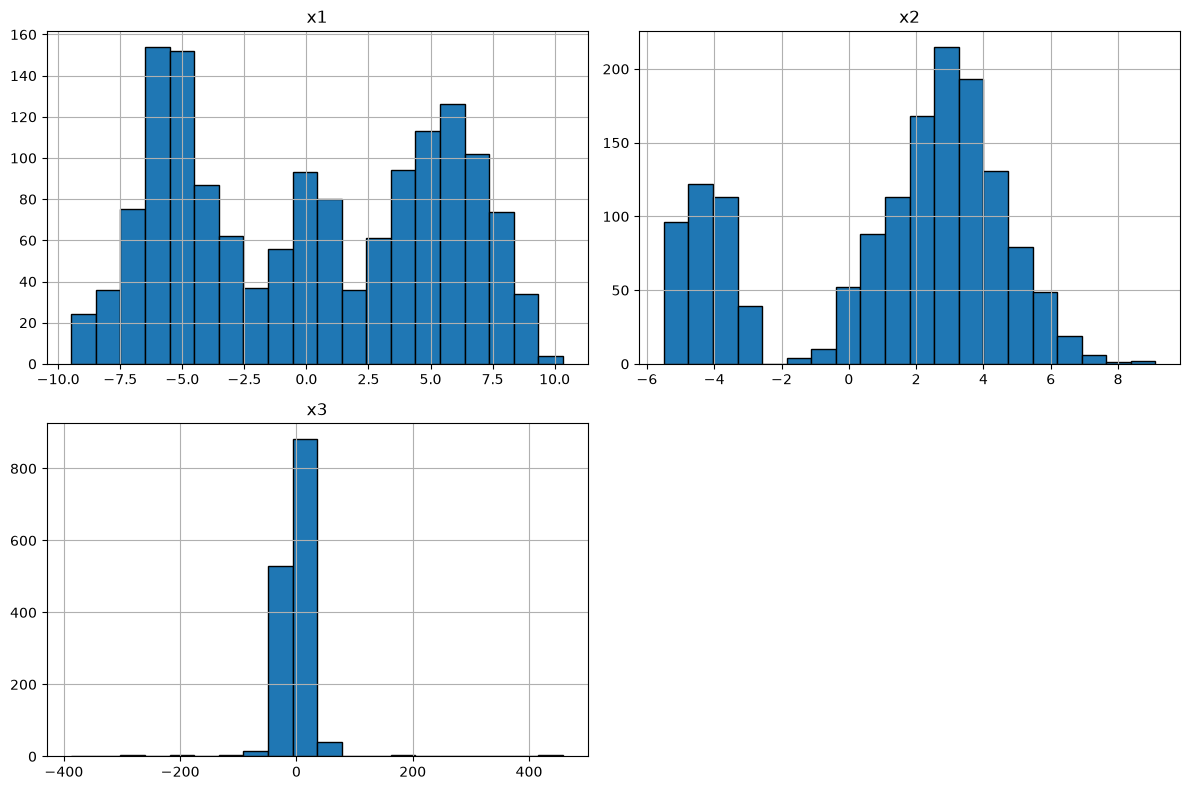

In [3]:
# Dibuja los histogramas de las variables x1, x2 y x3
df[['x1', 'x2', 'x3']].hist(bins=20, figsize=(12, 8), edgecolor='black')
plt.tight_layout()
plt.show()

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. Da la varianza de `x1`, `x2` y `x3` y el cociente de la de `x3` respecto a la media de las de `x1` y `x2`. ¿Qué forma tiene el histograma de `x3`? Apóyate en la mediana de `|x3|`, en su percentil 95 y en su máximo.
2. Interpreta la tabla: ¿qué modelos cambian su accuracy de forma apreciable al añadir `x3` sin escalar (b), y cuánto? ¿Qué parte de ese cambio recupera cada uno al escalar (c)?
3. Clasifica los diez modelos en sensibles e insensibles al escalado y justifica cada caso por cómo usa el modelo las variables (distancias, productos escalares, umbrales sobre cada variable, estimaciones por variable y clase, invariancia ante transformaciones lineales). Distingue el efecto de añadir `x3` del efecto de escalarla. ¿Algún modelo no se comporta como esperabas? Explícalo con tus cifras.
4. Tras escalar sigue habiendo una pérdida residual respecto a (a) en k-NN, SVM radial y SVM polinomial. ¿Por qué `x3` sigue estorbando aunque ya no domine las distancias? Apóyate en alguna cifra propia (por ejemplo, la distancia típica entre vecinos con y sin `x3`).
5. Compara los tres valores de `gamma='scale'` que has calculado y explica, en términos del ancho del kernel, qué implican para la SVM radial.
6. Explica cómo funciona tu `evaluate_cv`: con qué datos se ajusta cada paso (escalado, modelo, elección de hiperparámetros) y con qué datos se calcula la accuracy que devuelve.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej1_2'></a>
## 1.2. Comparación de modelos con búsqueda de hiperparámetros y fronteras (1 punto)

A partir de aquí **todos los modelos usan solo `x1` y `x2`** (`X2`). No se escalan: tienen escalas parecidas, y así las fronteras se dibujan en las unidades originales. Compararéis las diez familias de modelos con una búsqueda de hiperparámetros por familia (`GridSearchCV`, validación cruzada estratificada de 5 pliegues, métrica *accuracy*) y dibujaréis sus fronteras. Aquí se usa `GridSearchCV` directamente, y no `evaluate_cv`, porque se necesitan el mejor estimador, la desviación entre pliegues y las predicciones.

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Con las rejillas de `GRIDS` (definidas en la celda de código que sigue a esta caja), ejecuta `GridSearchCV` (`cv=CV`, `scoring='accuracy'`) para cada familia. Muestra una tabla ordenada con la accuracy CV de la mejor configuración, la desviación típica entre pliegues de esa configuración y sus hiperparámetros. Guarda el mejor estimador de cada familia en un diccionario `best_models`.
2. Con los mejores estimadores, obtén predicciones de validación cruzada (`cross_val_predict`) y calcula la accuracy **por región** (`LEFT`, `CENTER`, `RIGHT`, `BAND`, con `assign_region`) y el *recall* de cada clase.
3. Dibuja en una cuadrícula de 2x5 las fronteras de los diez mejores modelos (función `plot_boundary` con el argumento `ax`), con los puntos de entrenamiento superpuestos.
4. Dibuja en otra cuadrícula de 2x3 k-NN con `k` = 1, 15 y 51, y SVM radial con `C=10` y `gamma` = 0.03, 0.3 y 10. Para estos seis modelos da la accuracy sobre los propios datos de entrenamiento, la accuracy CV, la accuracy CV en `BAND` y el *recall* CV de la clase 2.
5. Ajusta LDA, QDA, naive Bayes y regresión logística **solo con los puntos de la región `LEFT` de las clases 0 y 1** y calcula su accuracy CV dentro de esa región. Calcula también la matriz de covarianzas (`np.cov`) y su determinante para cada una de esas dos clases en `LEFT`.
6. Para el árbol elegido, indica su número de hojas (`get_n_leaves()`).

Escribe el código en la celda de código bajo la caja Solución; puedes añadir más celdas de código debajo de ella.

</td></tr></table>

In [4]:
# One estimator and one hyperparameter grid for each model family.
GRIDS = {
    'k-NN':                (KNeighborsClassifier(),
                            {'n_neighbors': list(range(1, 52, 2)), 'weights': ['uniform', 'distance'],
                             'metric': ['euclidean', 'manhattan', 'chebyshev']}),
    'Linear SVM':          (SVC(kernel='linear'),            {'C': [0.1, 1, 10]}),
    'Polynomial SVM':      (SVC(kernel='poly', coef0=1),     {'degree': [2, 3, 4], 'C': [0.1, 1, 10]}),
    'RBF SVM':             (SVC(kernel='rbf'),               {'C': [0.1, 1, 10, 100], 'gamma': [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    'Sigmoid SVM':         (SVC(kernel='sigmoid'),           {'C': [0.1, 1, 10], 'gamma': [0.01, 0.1, 1]}),
    'Decision tree':       (DecisionTreeClassifier(random_state=0),
                            {'criterion': ['gini', 'entropy'],
                             'ccp_alpha': [0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02]}),
    'Naive Bayes':         (GaussianNB(),                    {}),
    'LDA':                 (LinearDiscriminantAnalysis(),    {}),
    'QDA':                 (QuadraticDiscriminantAnalysis(), {}),
    'Logistic regression': (LogisticRegression(max_iter=2000), {'C': [0.1, 1, 10]}),
}

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [5]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Qué dos familias obtienen mejor accuracy CV? Da sus cifras y la de la tercera, y compara la diferencia entre las dos primeras con su desviación entre pliegues.
2. Con la accuracy por región y el *recall* por clase, describe en qué regiones y en qué clases acierta y falla cada uno de los tres modelos de frontera lineal (SVM lineal, LDA y regresión logística), y relaciona lo que ves con la forma de sus fronteras en la cuadrícula de 2x5.
3. En la región `RIGHT`, compara la accuracy de SVM lineal, SVM polinomial, SVM radial y árbol. Describe la disposición de las clases en esa región a partir de las figuras y relaciónala con el número de hojas del árbol elegido.
4. Compara LDA y QDA en conjunto y dentro de `LEFT` (punto 5 de la Implementación), y compáralos dentro de `LEFT` con naive Bayes y la regresión logística. Relaciona las diferencias con las matrices de covarianzas y los determinantes de las clases 0 y 1 en `LEFT`.
5. En `BAND`, compara la accuracy CV de k-NN con `k=1`, `k=15`, `k=51` y el `k` elegido por la búsqueda. ¿Cómo cambia la forma de la frontera en esa región al variar `k`?
6. Con los seis modelos del punto 4 de la Implementación: compara el *recall* de la clase 2 para `k` = 1, 15 y 51; compara la accuracy de entrenamiento y la CV de la SVM radial para cada `gamma`; y describe la frontera en `BAND` con `gamma=0.03` y con `gamma=10`. Relaciona lo que ves con el ancho del kernel.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej1_3'></a>
## 1.3. Identificar el modelo (1 punto)

Se han entrenado seis modelos (distintas familias e hiperparámetros) con `datos_2d.csv` usando solo `x1` y `x2`, y se han dibujado sus fronteras en las imágenes `frontera_1.png` … `frontera_6.png`. En cada imagen las regiones coloreadas son lo que predice el modelo y los puntos son un **conjunto de test** (no son los datos de entrenamiento). Las imágenes no llevan título ni leyenda, y **están en orden aleatorio**. Los ejes y los colores son los de `plot_boundary` aplicada a `X2` (mismo rango y mismos colores por clase), por lo que podéis reproducirlas.

Pistas generales: las familias posibles son las de 1.2; para el kernel polinomial se ha usado `coef0=1` y cualquier hiperparámetro no mencionado en vuestra respuesta tiene su valor por defecto de scikit-learn.

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Muestra las seis imágenes con la celda de código dada.
2. Para cada imagen, elige una familia de modelos y unos hiperparámetros, entrena el modelo con `X2` e `y`, y dibuja su frontera con `plot_boundary(model, X2, ...)`. Coloca las seis figuras en una cuadrícula de 2×3, en el mismo orden que las imágenes, con la configuración elegida en el título de cada subfigura. Ajusta los hiperparámetros hasta que cada figura se parezca a su imagen.

Escribe el código del punto 2 en la celda de código bajo la caja Solución; puedes añadir más celdas de código debajo de ella.

</td></tr></table>

Image 1


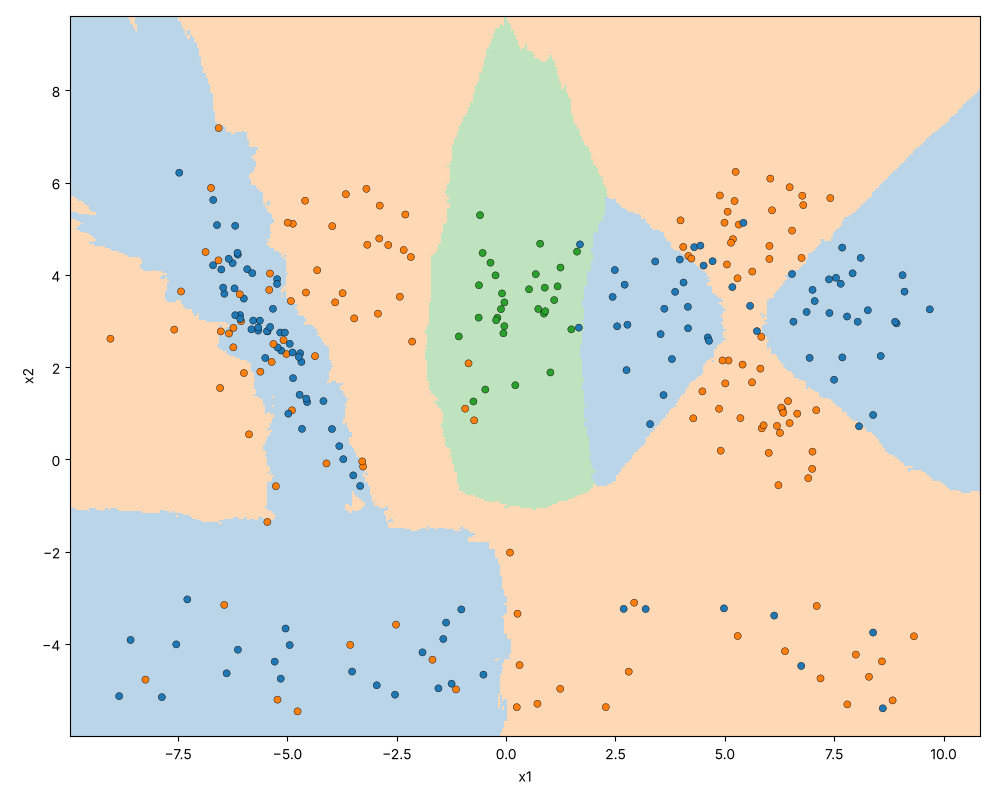

Image 2


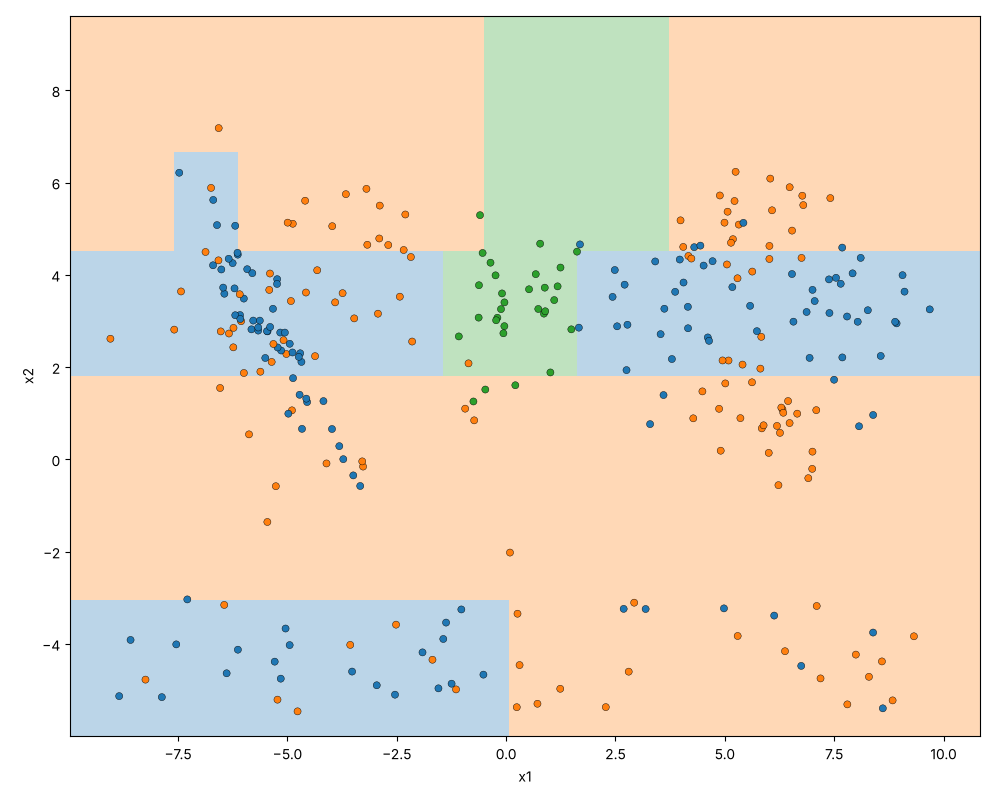

Image 3


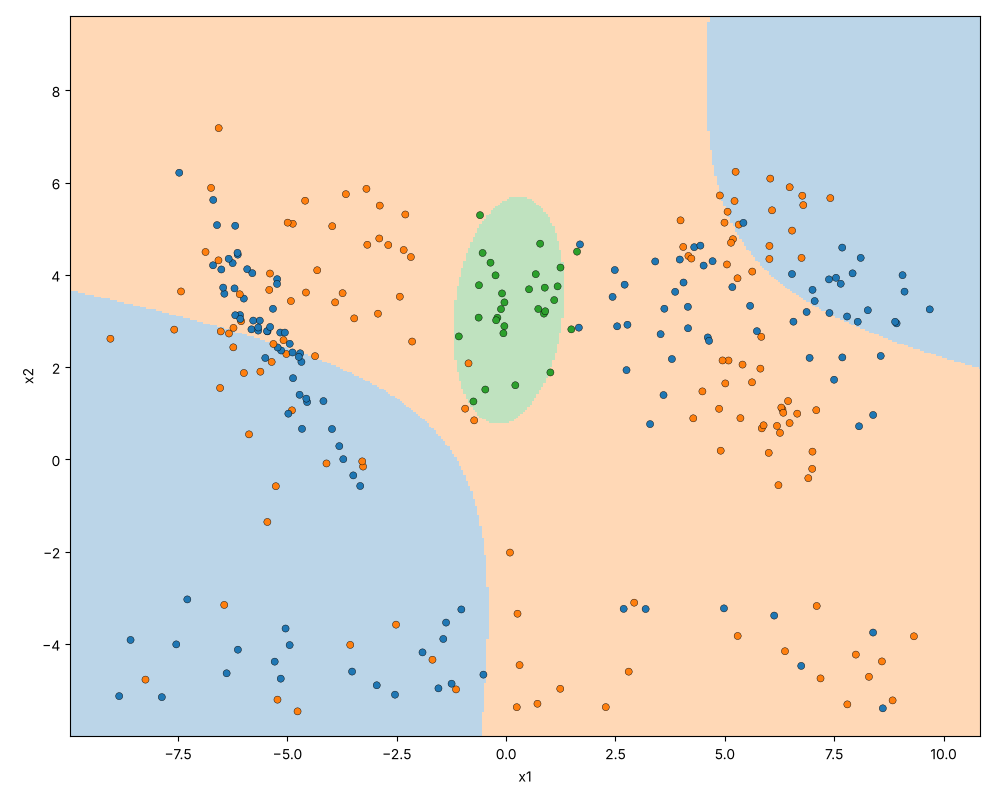

Image 4


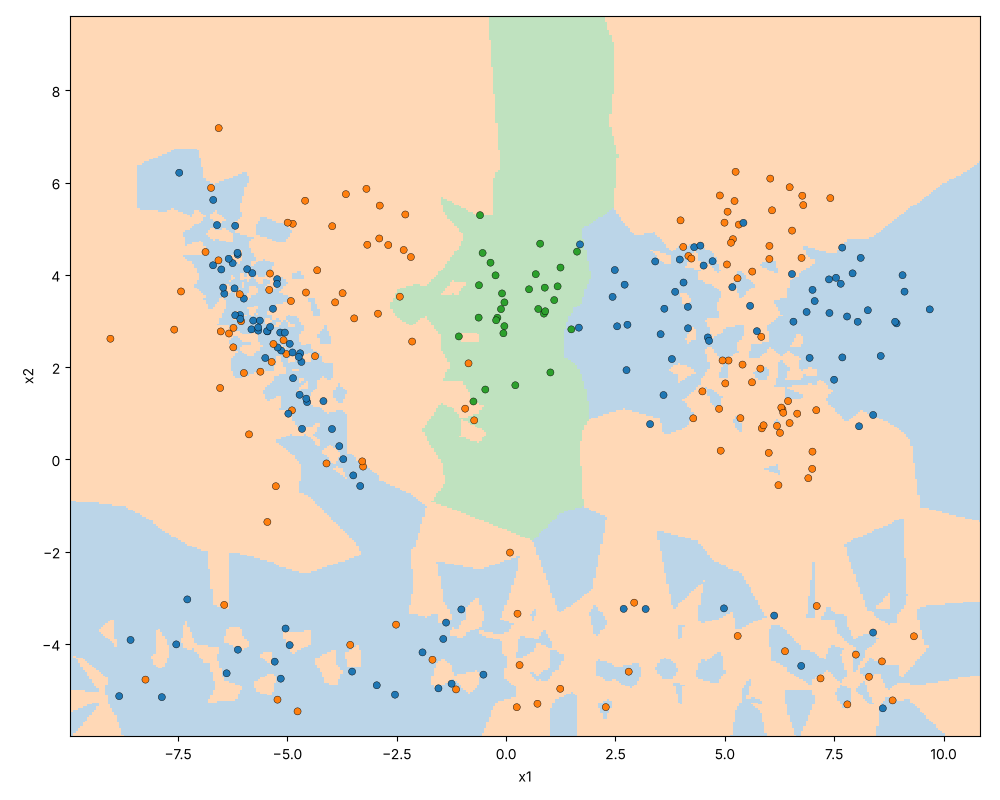

Image 5


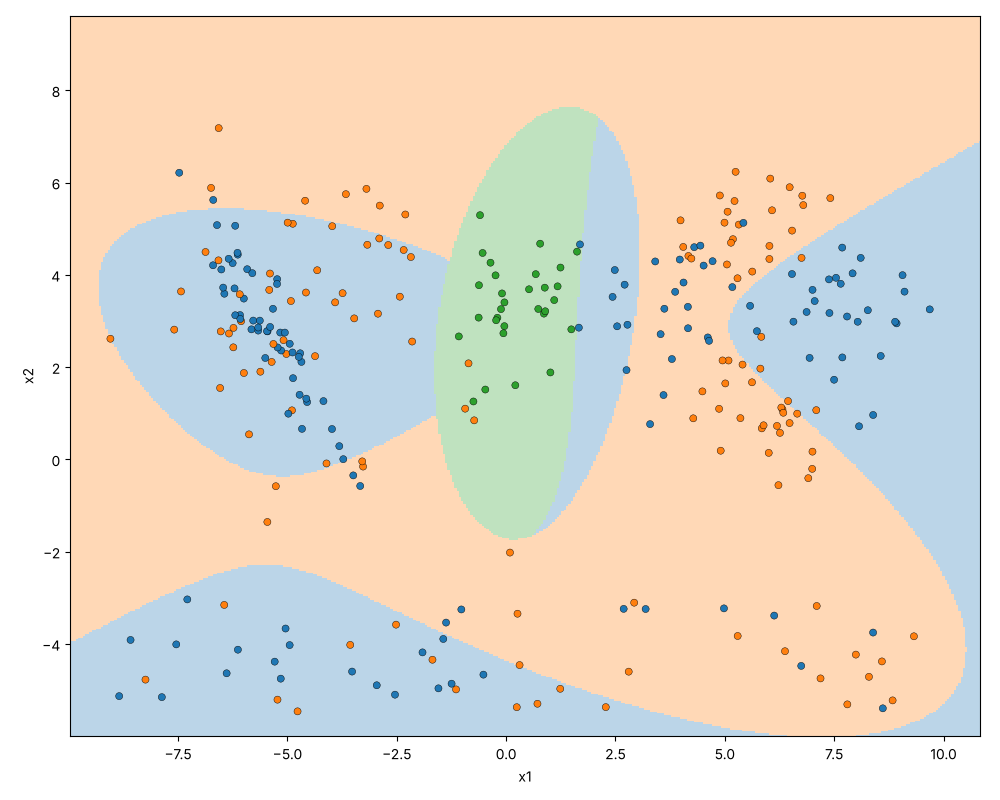

Image 6


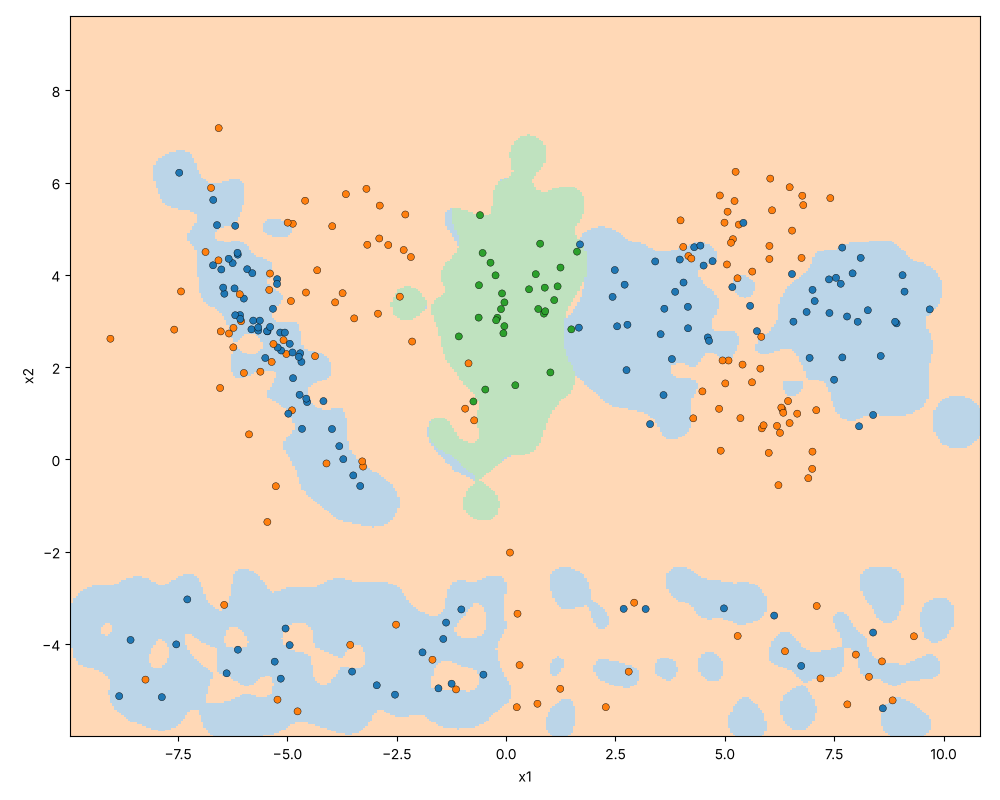

In [6]:
for k in range(1, 7):
    print('Image', k)
    display(Image('fotos/frontera_%d.png' % k, width=700))

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [7]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. Copia esta tabla en la caja Respuesta y complétala con una fila por imagen. En «Hiperparámetros» basta un valor aproximado o un rango (por ejemplo, «profundidad 4-6» o «C grande»); en «Rasgos», cita zonas concretas del plano (`LEFT`, `CENTER`, `RIGHT`, `BAND`) o coordenadas aproximadas.

    | Imagen | Familia | Hiperparámetros | Rasgos de la frontera que lo justifican |
    | --- | --- | --- | --- |
    | `frontera_1.png` | | | |
    | … | | | |
    | `frontera_6.png` | | | |

    Ejemplo de fila (con un modelo que no está entre los seis): `| frontera_k.png | LDA | sin hiperparámetros | Fronteras rectas entre las tres clases; en CENTER no aparece la clase 2 |`
2. Agrupa las seis imágenes según el tipo de frontera (rectas, segmentos paralelos a los ejes, curvas suaves, fronteras irregulares con regiones aisladas) y di qué familias son compatibles con cada grupo.
3. Elige las dos imágenes que más te ha costado distinguir. ¿Qué rasgo de la frontera las separa y en qué zona del plano se ve? ¿Qué experimento numérico (con una cifra, por ejemplo de accuracy) apoya tu decisión?
4. Para una imagen en la que el hiperparámetro sea difícil de precisar, reproduce la frontera con dos valores distintos y explica por qué es difícil fijarlo con exactitud a partir de la imagen.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej1_4'></a>
## 1.4. Sesgo y varianza con bootstrap (0,5 puntos)

Un modelo flexible ajusta muy bien la muestra de entrenamiento, pero su frontera cambia mucho si la muestra cambia (**varianza** alta). Un modelo regularizado cambia poco, pero puede equivocarse siempre de la misma manera (**sesgo** alto). Con `N_BOOT = 50` remuestreos bootstrap de los 1500 puntos (muestreo con reposición, con `np.random.default_rng(0)`; usad los **mismos** 50 remuestreos para los seis modelos) y los seis modelos de `BOOTSTRAP_MODELS` (árbol sin podar y podado, k-NN con `k=1` y `k=31` y SVM radial con `C=100` y `C=0.3`, con `gamma=1` en ambos) mediréis la varianza y razonaréis sobre el sesgo.

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Para cada modelo y cada remuestreo, ajusta el modelo con la muestra bootstrap (solo `x1` y `x2`), predice la clase en una malla de 100x100 puntos (`make_grid(X2, n=100)` y `predict_grid`) y predice los 1500 puntos originales.
2. Con esas predicciones, calcula para cada modelo las siguientes accuracy. Las dos primeras son *out-of-bag* (OOB): usan solo los puntos que **no** han entrado en la muestra bootstrap (en media, el 36.8 % de los puntos en cada remuestreo).
    - *Accuracy OOB por remuestreo*: en cada uno de los 50 remuestreos, la accuracy del modelo sobre los puntos que no están en esa muestra. Se resume con la media y la desviación de los 50 valores.
    - *Accuracy OOB por punto*: cada punto se evalúa solo con los modelos de los remuestreos en los que no entró (en media, unos 18 de los 50) y se obtiene su proporción de aciertos; después se promedia esa proporción sobre los puntos de cada región (`assign_region`).
    - *Accuracy de entrenamiento*: en cada remuestreo, la accuracy del modelo sobre los puntos de su propia muestra bootstrap (con las repeticiones); se resume con la media de los 50 valores.
3. Dibuja, en una cuadrícula de 2x3 (un panel por modelo), la **proporción de veces que cada punto de la malla se asigna a cada clase**: por ejemplo, una imagen RGB donde el color de cada punto es la mezcla de los colores de clase ponderada por esas proporciones (color puro = el modelo siempre decide lo mismo; color mezclado = inestable).
4. Resume en una tabla, por modelo: la accuracy OOB por remuestreo (media y desviación), la accuracy de entrenamiento, el **desacuerdo medio** en los puntos de datos (1 menos la proporción de remuestreos que votan la clase más votada en cada punto) en total y por región, la accuracy OOB por punto en cada región y, para los árboles, el nº medio de hojas y, para las SVM, el nº medio de vectores de soporte (`n_support_.sum()`).

Escribe el código en la celda de código bajo la caja Solución; puedes añadir más celdas de código debajo de ella.

</td></tr></table>

In [8]:
# The six models of this section (in pairs: flexible / regularized)
BOOTSTRAP_MODELS = {
    'Unpruned tree':            DecisionTreeClassifier(random_state=0),
    'Pruned tree (ccp 0.005)':  DecisionTreeClassifier(ccp_alpha=0.005, random_state=0),
    'k-NN k=1':                 KNeighborsClassifier(n_neighbors=1),
    'k-NN k=31':                KNeighborsClassifier(n_neighbors=31),
    'RBF SVM C=100':            SVC(kernel='rbf', C=100, gamma=1),
    'RBF SVM C=0.3':            SVC(kernel='rbf', C=0.3, gamma=1),
}
N_BOOT = 50   # number of bootstrap resamples

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [9]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. Ordena los seis modelos de mayor a menor desacuerdo medio. ¿Es relevante la diferencia de desacuerdo entre los tres modelos flexibles (árbol sin podar, k-NN con `k=1` y SVM con `C=100`)? ¿En qué región o regiones se concentra su inestabilidad? Da las cifras.
2. Árbol sin podar frente a árbol podado: compara el nº medio de hojas, el desacuerdo medio y la accuracy OOB. ¿En qué regiones reduce la poda el desacuerdo y en cuáles lo aumenta? Da las cifras de desacuerdo y de accuracy OOB por región.
3. Para cada uno de los seis modelos, compara la accuracy sobre la muestra de entrenamiento con la accuracy OOB. ¿Qué indica la diferencia y cómo se relaciona con el desacuerdo?
4. SVM radial `C=100` frente a `C=0.3`: compara la accuracy OOB, el desacuerdo medio y el nº medio de vectores de soporte. ¿Qué relación observas entre `C`, el nº de vectores de soporte y la estabilidad de la frontera?
5. Sesgo frente a ruido. (a) Calcula la fracción de puntos de `BAND` que quedan del lado «equivocado» de `x1 = 0` (el lado donde predomina la otra clase; determínalo con los datos) y compárala con la accuracy OOB y el desacuerdo de los seis modelos en `BAND`. ¿Qué parte del error de cada modelo en esa región parece ruido de las etiquetas y qué parte puede atribuirse al modelo? (b) En `RIGHT`, compara el árbol podado y la SVM `C=0.3` (accuracy OOB y desacuerdo): ¿la diferencia se explica solo por la varianza?

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2'></a>
# 2. Caso práctico: reingresos hospitalarios (5 puntos)

Trabajaremos con una base de ingresos hospitalarios de pacientes diabéticos en 130 hospitales de Estados Unidos entre 1999 y 2008. El objetivo es predecir, en el momento del alta, si el paciente volverá a ingresar en los 30 días siguientes, y decidir a qué pacientes conviene llamar por teléfono la semana siguiente al alta.

**Origen de los datos.** Los datos proceden de *Diabetes 130-US Hospitals for Years 1999-2008* (Clore, J., Cios, K., DeShazo, J. y Strack, B., 2014), UCI Machine Learning Repository, https://doi.org/10.24432/C5230J, con licencia CC BY 4.0. **La versión que se entrega ha sido modificada artificialmente.** No uséis la base original para completar, contrastar fila a fila ni recuperar etiquetas: las entregas que lo hagan se detectan y se califican con un 0 en toda la sección 2.

Recibís tres ficheros:

- `train.csv`: ingresos con la variable objetivo `readmitted_30` (1 si el paciente reingresó en menos de 30 días, 0 en otro caso).
- `test.csv`: ingresos de pacientes distintos, **sin** la variable objetivo. Es el test oculto: sus etiquetas no se entregan, y una parte de la nota se calcula automáticamente con vuestras predicciones.
- `codigos.csv`: significado de los códigos de `admission_type`, `discharge_disposition` y `admission_source`.

**Decisión que hay que tomar.** A cada paciente dado de alta se le puede llamar por teléfono la semana siguiente. Supondremos que la llamada evita el reingreso. Un reingreso no previsto cuesta 10 unidades y una llamada innecesaria cuesta 1; los aciertos no cuestan nada.

| | Reingresa | No reingresa |
| --- | --- | --- |
| Se le llama | 0 | 1 |
| No se le llama | 10 | 0 |

El coste de la llamada solo se cuenta cuando era innecesaria: si la llamada evita un reingreso, se compensa sobradamente, y por eso esa casilla vale 0.

Se recomienda revisar las siguientes referencias para ampliar estos temas y aplicarlos en este problema:

- [scikit-learn: Probability calibration](https://scikit-learn.org/stable/modules/calibration.html) y [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html), que incluye la definición del Brier score (Brier, 1950).
- Google, *Machine Learning Crash Course*: [Classification: ROC and AUC](https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc).
- Niculescu-Mizil, A. y Caruana, R. (2005). [Predicting good probabilities with supervised learning](https://citeseerx.ist.psu.edu/viewdoc/download?doi=10.1.1.60.7135&rep=rep1&type=pdf). *ICML 2005*.
- Lundberg, S. M. y Lee, S.-I. (2017). [A unified approach to interpreting model predictions](https://proceedings.neurips.cc/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html). *NeurIPS 2017*.
- Lundberg, S. M. et al. (2020). [From local explanations to global understanding with explainable AI for trees](https://pmc.ncbi.nlm.nih.gov/articles/PMC7326367/). *Nature Machine Intelligence*, 2, 56-67.

In [10]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Common seed for all the random procedures of this section
SEED = 2026
COST_FN, COST_FP = 10, 1

<a id='ej2_1'></a>
## 2.1. Carga y exploración orientada a decidir (0,5 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Carga `train.csv`, `test.csv` y `codigos.csv`. Revisa los valores de cada variable, incluidos los que indican que falta información.
2. Describe la estructura de los datos: número de ingresos y de pacientes, ingresos por paciente, prevalencia de la variable objetivo.
3. Identifica, con `codigos.csv`, los destinos del alta para los que el reingreso es imposible y decide qué hacer con esos ingresos.
4. Para cada variable, decide si su valor se conoce en el momento del alta. Construye cualquier variable adicional que te parezca útil y comprueba que también se podría calcular en ese momento. Calcula el AUC de cada variable por separado.
5. Compara `train.csv` y `test.csv` en una tabla con la proporción de cada valor en cada fichero y su diferencia, para `admission_source`, `admission_type`, `discharge_disposition`, `age` (por tramos), `sex` y número de ingresos por paciente, y con la media de cada variable numérica. Señala las tres diferencias más grandes.

Puedes añadir más celdas de código bajo la caja Solución.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [11]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Qué problemas de lectura y de codificación has encontrado y cómo los has resuelto?
2. ¿Qué variables no se conocen en el momento del alta, o permiten calcular algo que no se conoce? ¿Qué rendimiento darían si se usaran?
3. ¿Qué haces con los ingresos cuyo destino al alta es el fallecimiento? Justifícalo.
4. ¿En qué se diferencia `test.csv` de `train.csv` y qué consecuencias tendrá para estimar el rendimiento en el test?

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2_2'></a>
## 2.2. Validación honesta y comparación de modelos (0,5 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Prepara un `Pipeline` que incluya todo el preprocesamiento (codificación de categóricas, agrupación de diagnósticos, escalado cuando haga falta), de modo que se ajuste solo con los datos de entrenamiento de cada pliegue. Para agrupar los diagnósticos puedes usar la función `icd9_chapter` de la celda de código siguiente.
2. Compara con validación cruzada **agrupada por paciente** (`GroupKFold`, 5 pliegues) estos modelos: regresión logística, LDA, QDA, naive Bayes gaussiano, k-NN, árbol de decisión y SVM con kernel radial. Ajusta los hiperparámetros principales de cada uno con `GridSearchCV`, también agrupado y con `scoring="roc_auc"`. Para k-NN y SVM puedes usar una submuestra de pacientes; indica su tamaño. El modelo que elijas para el resto de la sección debe ser de una de estas familias.
3. Para el modelo elegido, estima su AUC con **validación cruzada anidada** y compárala con la que da la búsqueda de hiperparámetros.
4. Repite la estimación del modelo elegido con `KFold` por filas, sin agrupar, y con todas las variables que construiste en 2.1, incluidas las que descartaste por no conocerse en el momento del alta. Compara las tres estimaciones.

Puedes añadir más celdas de código bajo la caja Solución.

</td></tr></table>

In [12]:
# Given code: do not modify
def icd9_chapter(code):
    """Group an ICD-9 diagnosis code into a disease chapter, following the grouping
    of Strack et al. (2014)."""
    if pd.isna(code):
        return "missing"
    if code.startswith(("V", "E")):
        return "other"
    x = float(code)
    if 250 <= x < 251: return "diabetes"
    if 390 <= x < 460 or int(x) == 785: return "circulatory"
    if 460 <= x < 520 or int(x) == 786: return "respiratory"
    if 520 <= x < 580 or int(x) == 787: return "digestive"
    if 800 <= x < 1000: return "injury"
    if 710 <= x < 740: return "musculoskeletal"
    if 580 <= x < 630 or int(x) == 788: return "genitourinary"
    if 140 <= x < 240: return "neoplasms"
    return "other"

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [13]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Qué modelo eliges y por qué? Ten en cuenta el AUC, su variabilidad entre pliegues, el coste computacional y la interpretabilidad.
2. Compara la AUC que da la búsqueda de hiperparámetros con la de la validación anidada. ¿Cuánto difieren en tu caso y a qué lo atribuyes?
3. Explica la diferencia entre las tres estimaciones (la de la búsqueda, la anidada y la del punto 4 de la Implementación) y cuál usarías para anticipar el resultado en el test oculto.
4. ¿Qué hipótesis de cada modelo explica su posición en la comparación?

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2_3'></a>
## 2.3. Decisión con la matriz de costes (0,25 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Obtén, para cada ingreso de `train.csv`, la probabilidad de reingreso que da un modelo que no ha visto a ese paciente durante el entrenamiento (predicción fuera de muestra, en inglés *out-of-fold*). Usa `cross_val_predict` con `method="predict_proba"` y `GroupKFold` de 5 pliegues, agrupando por paciente: cada pliegue se predice con el modelo entrenado con los otros cuatro. No uses las probabilidades del modelo entrenado con todo `train.csv` sobre los mismos datos, porque serían optimistas.
2. Calcula el umbral teórico a partir de la matriz de costes. Calcula el coste medio por paciente y la accuracy en cuatro casos: con ese umbral, con el umbral 0,5, llamando a todos los pacientes y sin llamar a ninguno.
3. Muestra la matriz de confusión con el umbral teórico y el porcentaje de pacientes a los que se llama.
4. Calcula el Brier de las probabilidades fuera de muestra.

El Brier es la media de los cuadrados de la diferencia entre la probabilidad predicha y el resultado 0/1; mide a la vez lo bien que el modelo ordena y lo calibradas que están sus probabilidades, y cuanto menor, mejor.

El umbral teórico solo es óptimo si las probabilidades del modelo están bien calibradas, es decir, si entre los pacientes a los que el modelo asigna, por ejemplo, un 20 % de riesgo reingresa aproximadamente un 20 %. Una puntuación que no es una probabilidad (por ejemplo, la salida de `decision_function` de una SVM reescalada a [0, 1]) no sirve para aplicar este umbral. Para ampliar el tema de la calibración, véanse las referencias de scikit-learn y de Niculescu-Mizil y Caruana de la introducción de la sección.

El modelo es el elegido en 2.2. Puedes añadir más celdas de código bajo la caja Solución (por ejemplo, para los cálculos que piden las preguntas del Análisis).

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [14]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Qué umbral obtienes y por qué es tan distinto de 0,5? ¿Qué ocurre con el coste y con la accuracy al usar 0,5?
2. ¿Cuánto ahorra el modelo respecto a llamar a todos y respecto a no llamar a nadie? ¿Compensa usarlo con esta matriz de costes?
3. Si la llamada costara más (por ejemplo, 3 en lugar de 1), ¿cómo cambiarían el umbral y la proporción de pacientes a los que se llama? Calcúlalo con tus predicciones.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2_4'></a>
## 2.4. Efectos de las variables, interpretación y contraste con la literatura (1,25 puntos)

**Interpretar un modelo.** Además de predecir bien, queremos saber qué variables influyen en las predicciones del modelo y cómo. En este apartado compararéis tres formas de medirlo, que no responden exactamente a la misma pregunta:

- **Importancia por impureza.** Mide cuánto reduce cada variable la impureza (Gini o entropía) en los cortes del árbol en que interviene. Se calcula con los datos de entrenamiento y es propia de los árboles.
- **Importancia por permutación.** Mide cuánto empeora una métrica, por ejemplo el AUC, en datos de validación cuando se desordenan al azar los valores de una variable. Sirve para cualquier modelo.
- **Valores de Shapley (SHAP).** Reparten la predicción de cada caso entre las variables, de modo que se puede ver qué ha empujado la predicción de un paciente concreto hacia arriba o hacia abajo.

**Cómo funciona SHAP.** La idea viene de la teoría de juegos cooperativos (Shapley, 1953): cómo repartir de forma justa el resultado de un juego entre los jugadores que han colaborado. Aquí los «jugadores» son las variables y el «resultado» es la predicción. Para un caso x, la predicción se descompone como f(x) = φ₀ + φ₁ + … + φₚ, donde φ₀ es la predicción media del modelo y φⱼ es la contribución de la variable j en ese caso. Cada φⱼ es la contribución media de la variable j cuando se añade a todos los subconjuntos posibles de las demás variables. Calcularlo así exige un número de evaluaciones que crece exponencialmente con el número de variables. Para árboles, `shap.TreeExplainer` lo calcula de forma exacta y rápida aprovechando la estructura del árbol. El resultado es un valor por caso y por variable. Su media en valor absoluto se usa como importancia global, y el gráfico `summary_plot` muestra a la vez la magnitud y el sentido de cada efecto.

**Precauciones.** Las tres medidas describen el modelo, no la realidad: una variable importante no es necesariamente causa del reingreso. Cuando dos variables están correlacionadas, cada método reparte su efecto de forma distinta.

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Calcula, con la población definida en 2.1 (sin fallecidos), la tasa de reingreso según: la medición de la HbA1c y su resultado; los días de ingreso; los ingresos previos en cada tramo de edad (menos de 60, 60-69, 70 o más); y el destino del alta.
2. Calcula la importancia por permutación sobre el modelo elegido en 2.2 (sobre un pliegue de validación), y la importancia por impureza y los valores de Shapley sobre el mejor árbol del 2.2 (con la librería `shap`).
3. Busca al menos una fuente publicada sobre esta base de datos o sobre reingresos de pacientes diabéticos. Cítala con DOI o enlace.

Puedes añadir más celdas de código bajo la caja Solución.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [15]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Cómo se relaciona la medición de la HbA1c con el reingreso **en estos datos**?
2. ¿Es lineal el efecto de los días de ingreso?
3. ¿Depende el efecto de los ingresos previos de la edad del paciente? ¿Qué modelos pueden captar esa dependencia y cuáles no sin variables adicionales?
4. ¿Qué destinos del alta tienen mayor y menor tasa de reingreso?
5. Elige dos de estos hallazgos y contrástalos con la fuente publicada que hayas encontrado. Cita la frase concreta de la fuente que respalda la comparación y explica las coincidencias o diferencias.
6. Compara las cinco variables más importantes según cada método (y cada modelo). ¿Coinciden? Explica las diferencias con tus cifras.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2_5'></a>
## 2.5. Equidad (0,25 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

Toma la edad como atributo protegido, con los tramos menos de 60, 60-69, 70-79 y 80 o más. Se elige la edad porque es un factor de riesgo clínico real y aquí el riesgo de reingreso cambia mucho con ella, lo que permite ver el conflicto entre criterios de equidad.

1. Con las predicciones fuera de muestra del modelo elegido y el umbral del apartado 2.3, calcula para cada tramo la tasa base, la TPR, la FPR y la proporción de pacientes a los que se llama.
2. Calcula, para cada tramo, la probabilidad media predicha y la tasa de reingreso observada.
3. Busca umbrales por tramo que igualen la TPR de cada tramo a la TPR global del modelo con el umbral único, y calcula el coste medio resultante.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [16]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Cumple el modelo la condición de independencia (misma proporción de llamadas por tramo)? ¿Y la de separación (misma TPR y FPR)? ¿Están calibradas las probabilidades en cada tramo (probabilidad media igual a la tasa observada)? Esta última es una comprobación parcial de la condición de suficiencia, que exige que, a igual probabilidad predicha, la tasa de reingreso sea la misma en todos los tramos.
2. Con tus tasas base, TPR, FPR y calibración por tramo, muestra con cifras por qué no se cumplen a la vez.
3. ¿Qué se gana y qué se pierde al igualar la TPR con umbrales por tramo? ¿Lo aplicarías en este problema?

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2_6'></a>
## 2.6. Estimación del resultado en el test oculto (0,25 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

Estima el AUC, el Brier y el coste medio por paciente que obtendréis en el test oculto, cada uno con un intervalo de confianza del 95 %. La estimación debe tener en cuenta las diferencias entre `train.csv` y `test.csv` que encontraste en 2.1. El coste se calcula con el umbral elegido en 2.3.

El intervalo debe reflejar también que `test.csv` es una muestra de un tamaño concreto: el resultado en el test variaría aunque supierais exactamente cuánto rinde el modelo en promedio sobre pacientes como los del test.

Puedes añadir más celdas de código bajo la caja Solución.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [17]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. Explica cómo has construido la estimación y el intervalo de cada métrica, y qué cifras de 2.1 has tenido en cuenta.
2. Si te equivocas, ¿en qué sentido crees que será el error (resultado en el test mejor o peor que tu estimación) y por qué?

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej2_7'></a>
## 2.7. Entrega de predicciones para el test oculto (2 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

Entrena el modelo elegido con todo `train.csv` y aplícalo a `test.csv`. Aplica a `test.csv` las mismas decisiones que tomaste en 2.1 (población, lectura de los datos, variables descartadas); el fichero de predicciones debe tener una fila por cada ingreso de `test.csv`, también por los que decidas no incluir en el entrenamiento. La columna `decision` se calcula con el umbral elegido en 2.3.

Guarda tu identificador de estudiante en una variable `ID` y genera dos ficheros, que se suben junto con el notebook y el HTML:

1. `<tu_identificador>_predicciones.csv`, con una fila por ingreso de `test.csv` y las columnas `admission_id`, `probability` (entre 0 y 1) y `decision` (1 = llamar).
2. `<tu_identificador>_estimacion.csv`, con las columnas `metric`, `value`, `ci_lower` y `ci_upper` y una fila para cada métrica: `auc`, `brier` y `cost`. Son las estimaciones del apartado 2.6, hechas antes de conocer el resultado.

Este apartado se puntúa automáticamente con las etiquetas del test: 1 punto por el rendimiento (AUC y coste medio por paciente) y 1 punto por la precisión de las estimaciones del apartado 2.6, es decir, por lo cerca que queden del resultado real y por si los intervalos lo contienen; un intervalo excesivamente ancho no cuenta. Una entrega sin las columnas indicadas, o a la que le falte más del 1 % de los ingresos de `test.csv`, no se puede puntuar. Después de la caja Solución hay una celda que comprueba el formato de los dos ficheros.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [18]:
#############################################
# SOLUTION                                  #
#############################################

In [19]:
# Format check of the two submission files (do not modify)
# Uses the variable ID (your student identifier, as in the file names) defined in your code above
pred = pd.read_csv(f"{ID}_predicciones.csv")
est_file = pd.read_csv(f"{ID}_estimacion.csv")
test_ids = pd.read_csv("test.csv", usecols=["admission_id"]).admission_id
problems = []
if list(pred.columns) != ["admission_id", "probability", "decision"]:
    problems.append(f"Wrong columns in predictions: {list(pred.columns)}")
else:
    if set(pred.admission_id) != set(test_ids) or pred.admission_id.duplicated().any():
        problems.append("admission_id must contain each test id exactly once")
    if not pred.probability.between(0, 1).all():
        problems.append("probability must be between 0 and 1")
    if not pred.decision.isin([0, 1]).all():
        problems.append("decision must be 0 or 1")
if list(est_file.columns) != ["metric", "value", "ci_lower", "ci_upper"]:
    problems.append(f"Wrong columns in estimation file: {list(est_file.columns)}")
elif sorted(est_file.metric) != ["auc", "brier", "cost"]:
    problems.append("metric must contain auc, brier and cost, one row each")
elif not (est_file.ci_lower <= est_file.value).all() or not (est_file.value <= est_file.ci_upper).all():
    problems.append("ci_lower <= value <= ci_upper must hold in every row")
print("Format OK" if not problems else "\n".join(problems))

NameError: name 'ID' is not defined

<a id='ej3'></a>
# 3. Auditoría de una solución hecha por IA (2 puntos)

El equipo de tutoría de una universidad en línea quiere detectar, en la semana 4 del semestre, las matrículas con riesgo de abandono para contactar a esos estudiantes. Puede contactar como máximo al **10 %** de las matrículas, y necesita además una previsión del número total de abandonos del semestre para planificar sus recursos.

Un asistente de IA generativa ha resuelto este encargo en `notebook_auditoria.ipynb`, con los datos de `enrollments.csv`. Los datos son sintéticos: se han generado para esta práctica y no corresponden a estudiantes reales. El notebook se ejecuta de principio a fin sin errores (unos tres minutos), está bien presentado y llega a sus conclusiones con seguridad.

**El notebook contiene varios errores metodológicos.** No se dice cuántos ni dónde están. El objetivo de esta sección es encontrarlos, explicarlos, corregirlos y medir cuánto cambian los resultados al corregirlos. Que un código no falle y que sus cifras parezcan buenas no demuestra que el análisis sea correcto.

**Datos.** Cada fila de `enrollments.csv` es una matrícula: un estudiante en una asignatura en un semestre. Todas las variables se miden hasta la semana 4.

| Variable | Descripción |
| --- | --- |
| `student_id` | Identificador del estudiante |
| `enrollment_id` | Identificador de la matrícula |
| `age` | Edad |
| `access_route` | Vía de acceso: `Bachillerato`, `FP`, `Mayores25` (prueba de acceso para mayores de 25 años) o `Titulados` |
| `scholarship` | Tiene beca (`yes`, `no`) |
| `hours_work_week` | Horas de trabajo remunerado por semana declaradas en la matrícula |
| `credits_enrolled` | Créditos matriculados en el semestre |
| `previous_fails` | Asignaturas suspendidas en semestres anteriores |
| `logins_week` | Accesos semanales al campus (media de las semanas 1 a 4) |
| `forum_posts` | Mensajes en el foro de la asignatura |
| `tutor_contacts` | Contactos con el tutor, incluido el del piloto |
| `tutor_pilot` | 1 si la matrícula entró en el piloto de tutoría: al 20 % de las matrículas, elegidas al azar, el tutor les hizo un contacto proactivo en la semana 2 |
| `pec1_grade` | Nota de la PEC1 (de 0 a 10); vacía si no se entregó |
| `dropout` | 1 si el estudiante abandonó la asignatura (no se presentó a la evaluación final) |

**Cómo trabajar**

- Colocad `notebook_auditoria.ipynb` en la misma carpeta que `enrollments.csv` y ejecutadlo. Sus celdas de código llevan un comentario `# [C1]`, `# [C2]`, ... y sus apartados de texto están numerados: usad esas referencias en vuestras respuestas.
- No hay que entregar el notebook corregido. Las correcciones se programan en la celda de código bajo la caja Solución de cada apartado (podéis añadir más celdas de código debajo) y se explican en la caja Respuesta de cada apartado.
- Los errores pueden estar en cualquier fase del análisis, desde la preparación de los datos hasta las conclusiones. También cuentan los problemas que no estén previstos, siempre que los justifiquéis con cifras propias.
- Las cifras de esta sección tienen que ser vuestras: obtenidas ejecutando código, no copiadas del texto del asistente. Las afirmaciones del notebook, por seguras que suenen, no son evidencia.

<a id='ej3_1'></a>
## 3.1. Revisión del notebook (0,5 puntos)

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Ejecutad `notebook_auditoria.ipynb` y anotad las cifras que presenta como resultado: *accuracy* esperada con estudiantes nuevos, AUC, matrículas que se contactarán, abandonos esperados en el semestre y entre los contactados.
2. Revisad el notebook celda a celda (código, salidas y texto) y localizad los pasos metodológicamente incorrectos o no justificados.

Si necesitáis calcular alguna cifra auxiliar, hacedlo en la celda de código bajo la caja Solución (podéis añadir más celdas de código debajo).

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [ ]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

Copiad en la caja Respuesta de este apartado la tabla siguiente, con una fila por problema encontrado (añadid las filas que necesitéis), y responded a las preguntas debajo de ella.

| Problema | Celda [Cn] | Qué hace | Por qué es un error | Consecuencia sobre las cifras o las conclusiones |
| --- | --- | --- | --- | --- |
| | | | | |
| | | | | |

1. Comparad las cifras que presenta el notebook con una referencia sencilla que elijáis vosotros. ¿Cuáles os parecen creíbles y cuáles no? Apoyaos en cifras.
2. Ordenad los problemas que habéis encontrado de más a menos graves por su efecto sobre la decisión del equipo de tutoría y sobre sus conclusiones, y justificad el orden.
3. Clasificad los problemas que habéis encontrado según su tipo y explicad qué cambia en el diagnóstico y en la corrección de cada tipo.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej3_2'></a>
## 3.2. Corrección y cuantificación (1,25 puntos)

El notebook entrena con una muestra de 2.500 estudiantes (celda C7). Los demás, que el modelo no ha visto, hacen de estudiantes del próximo semestre: con ellos se puede medir qué pasaría de verdad al aplicar cada versión del análisis. La celda de código siguiente los separa en `NEW_STUDENTS` y define la función `evaluate_decision()`, que recibe las matrículas de estudiantes nuevos que puntúa una versión y su riesgo, contacta a las `CAPACITY` matrículas de más riesgo (el 10 % de las de estudiantes nuevos) y devuelve el AUC, los abandonos alcanzados, la precisión de los contactos y la previsión (suma de los riesgos) frente a los abandonos reales. Usadla para medir todas las versiones.

In [ ]:
# Given code: do not modify
# Students that the audited notebook does not use to train (cell C7): they play the role of next
# semester's students. evaluate_decision() measures a contact decision on them.
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

enrollments_audit = pd.read_csv("enrollments.csv")
SAMPLE_AUDIT = np.random.default_rng(42).choice(
    enrollments_audit.dropna()["student_id"].unique(), size=2500, replace=False)
NEW_STUDENTS = enrollments_audit.loc[~enrollments_audit["student_id"].isin(SAMPLE_AUDIT)]
CAPACITY = int(0.10 * len(NEW_STUDENTS))   # enrollments the tutoring team can contact


def evaluate_decision(enrollment_id, risk):
    """enrollment_id: identifiers of the new students' enrollments that a version scores (all of
    them, or fewer if it drops rows). risk: the risk of each one (a probability, if it is used to
    forecast). Contacts the CAPACITY enrollments with the highest risk and compares the forecast
    (sum of the risks) with the real dropouts of all the new students."""
    y = NEW_STUDENTS.set_index("enrollment_id").loc[enrollment_id, "dropout"].to_numpy()
    risk = np.asarray(risk, dtype=float)
    top = np.argsort(-risk)[:CAPACITY]
    return pd.Series({
        "scored enrollments": len(y),
        "AUC (scored enrollments)": roc_auc_score(y, risk),
        "contacts": len(top),
        "dropouts reached": int(y[top].sum()),
        "precision of the contacts": y[top].mean(),
        "forecast (sum of risks)": risk.sum(),
        "real dropouts (all new students)": int(NEW_STUDENTS["dropout"].sum()),
    })

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Implementación:</strong>

1. Para cada problema de vuestra tabla del 3.1 que cambie alguna cifra, corregidlo **por separado**: partid del código del notebook, corregid solo ese problema y dejad los demás como están, con las mismas semillas, muestra e hiperparámetros. Medid el resultado con `evaluate_decision()` y recalculad también la cifra del notebook que ese problema afecta (por ejemplo, el AUC de su validación o su previsión).
2. Corregid todos los problemas a la vez, con la misma SVM, y medid el resultado.
3. Con todo corregido, volved a elegir los hiperparámetros de la SVM con una validación correcta y medid el resultado. Comparadlo con al menos otra familia de modelos y con alguna regla sencilla que no use un modelo.

Programad las correcciones en la celda de código bajo la caja Solución (podéis añadir más celdas de código debajo).

</td></tr></table>

<table width="100%"><tr><td bgcolor="#f2dede" style="border-left:6px solid #a94442; color:#4a1515; padding:10px 14px;">

🟥 <strong>Solución:</strong>

</td></tr></table>

In [ ]:
#############################################
# SOLUTION                                  #
#############################################

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. Copiad esta tabla en la caja Respuesta y completadla con una fila por problema y una fila con todo corregido:

| Problema | Celda | Cifra del notebook afectada: notebook → corregido | Abandonos alcanzados: notebook → corregido | Previsión: notebook → corregido |
| --- | --- | --- | --- | --- |
| | | | | |
| | | | | |

2. ¿Qué problemas cambian sobre todo lo que el notebook dice de su rendimiento y cuáles cambian lo que pasa de verdad con los estudiantes nuevos? ¿Hay alguno con un efecto casi nulo en este caso? ¿Por qué sigue siendo un error y en qué situación pesaría más?
3. Elegid dos problemas cuya corrección afecte a la misma cifra. Corregidlos por separado y juntos: ¿se suman sus efectos? ¿Por qué? (Añadid las celdas de código que necesitéis bajo la caja Solución.)
4. Con todo corregido, ¿cuántos abandonos alcanzaría el equipo con sus contactos y qué previsión le daríais? ¿Qué parte de la mejora se debe a corregir los errores y qué parte a cambiar los hiperparámetros o el modelo?

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='ej3_3'></a>
## 3.3. Conclusiones (0,25 puntos)

En este apartado no hay que programar nada: con todos los problemas corregidos (apartado 3.2) y vuestros propios resultados, responded a las preguntas en la caja Respuesta.

<table width="100%"><tr><td bgcolor="#d9edf7" style="border-left:6px solid #31708f; color:#0c3c5a; padding:10px 14px;">

🟦 <strong>Análisis:</strong>

1. ¿Qué conclusiones del notebook se mantienen después de corregirlo todo y cuáles no? Apoyad cada una en una cifra vuestra.
2. ¿Qué modelo elegiríais ahora y qué resultado esperaríais con los estudiantes del próximo semestre (abandonos alcanzados con los contactos del equipo y previsión)?
3. ¿Qué recomendaríais a la universidad sobre los contactos con el tutor? Apoyad la respuesta en los datos.
4. Escribid entre cuatro y seis instrucciones concretas y comprobables que habría que haberle dado al asistente de IA para evitar los errores, y las comprobaciones que haríais siempre antes de fiaros de un análisis generado por una IA.

</td></tr></table>

<table width="100%"><tr><td bgcolor="#dff0d8" style="border-left:6px solid #3c763d; color:#1e3a1e; padding:10px 14px;">

🟩 <strong>Respuesta:</strong>

&nbsp;

&nbsp;

&nbsp;

&nbsp;

</td></tr></table>

<a id='declaracion_ia'></a>
## Declaración de uso de IA

Completad una fila por cada uso. Si no habéis usado ninguna herramienta de IA, indicadlo en la primera fila.

| Apartado | Herramienta y modelo | Para qué se ha usado | Qué habéis modificado de lo que propuso |
| --- | --- | --- | --- |
| | | | |
| | | | |
| | | | |